# Random Forest — Detección de fraude (Caso 1)

Se importan las librerías y la configuración compartida desde comun.py.

In [1]:
import sys
sys.path.append("..")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import confusion_matrix, precision_recall_curve, average_precision_score
from comun.comun import (RANDOM_STATE, CV, SCORING, cargar_train, make_prep,
                         guardar, resumen_cv, guardar_resultados)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.4f}".format)

Se carga el conjunto de entrenamiento con las 15 predictoras finales.

In [2]:
X, y = cargar_train()
print(f"X: {X.shape[0]:,} filas x {X.shape[1]} predictoras | fraudes: {y.sum()} ({y.mean()*100:.3f}%)")

X: 40,000 filas x 15 predictoras | fraudes: 727 (1.818%)


## 1. Pipeline

Se arma el pipeline con One-Hot para las categóricas, sin escalado porque los árboles no lo necesitan, y un Random Forest de 300 árboles con pesos balanceados en cada muestra bootstrap para compensar el desbalance de clases.

In [3]:
pipe = Pipeline([
    ("prep", make_prep(escalar=False)),
    ("modelo", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                      random_state=RANDOM_STATE, n_jobs=1)),
])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{tra

## 2. Validación cruzada y ajuste de hiperparámetros

Se buscan la profundidad máxima, el mínimo de transacciones por hoja, la fracción de variables por corte y el peso de la clase fraude con validación cruzada estratificada de 5 folds sobre train, registrando también el rendimiento en entrenamiento para detectar sobreajuste.

In [4]:
grid = GridSearchCV(pipe, {"modelo__max_depth": [6, 10, None],
                           "modelo__min_samples_leaf": [20, 50, 100, 200],
                           "modelo__max_features": ["sqrt", 0.5],
                           "modelo__class_weight": ["balanced_subsample", {0: 1, 1: 10}]},
                    cv=CV, scoring=SCORING, refit="pr_auc", return_train_score=True, n_jobs=-1)
grid.fit(X, y)
print(f"Mejores parámetros: {grid.best_params_} | PR-AUC CV: {grid.best_score_:.4f}")

Mejores parámetros: {'modelo__class_weight': {0: 1, 1: 10}, 'modelo__max_depth': 6, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 50} | PR-AUC CV: 0.0535


Se muestran las 10 mejores combinaciones según PR-AUC, con el rendimiento en entrenamiento y validación y el cociente entre ambos como medida de sobreajuste.

In [5]:
cvr = pd.DataFrame(grid.cv_results_)
(cvr.assign(peso=cvr["param_modelo__class_weight"].astype(str),
            max_depth=cvr["param_modelo__max_depth"].astype(str),
            min_samples_leaf=cvr["param_modelo__min_samples_leaf"],
            max_features=cvr["param_modelo__max_features"].astype(str),
            sobreajuste=cvr["mean_train_pr_auc"] / cvr["mean_test_pr_auc"])
    .set_index(["peso", "max_depth", "min_samples_leaf", "max_features"])
    [["mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "sobreajuste", "mean_test_roc_auc"]]
    .rename(columns=lambda c: c.replace("mean_", "").replace("test_", "val_"))
    .sort_values("val_pr_auc", ascending=False).head(10))

train_pr_auc  \
peso               max_depth min_samples_leaf max_features                 
{0: 1, 1: 10}      6         50               sqrt                0.1206   
                             20               sqrt                0.1530   
                   10        20               sqrt                0.3788   
                   6         100              sqrt                0.0978   
                   nan       100              sqrt                0.1507   
                   10        50               sqrt                0.2076   
                             200              sqrt                0.0917   
                             100              sqrt                0.1316   
                   6         200              sqrt                0.0783   
balanced_subsample 6         200              sqrt                0.0838   

                                                            val_pr_auc  \
peso               max_depth min_samples_leaf max_features               
{0: 1, 1: 10}      6         50               sqrt              0.0535   
                             20               sqrt              0.0532   
                   10        20               sqrt              0.0525   
                   6         100              sqrt              0.0523   
                   nan       100              sqrt              0.0521   
                   10        50               sqrt              0.0519   
                             200              sqrt              0.0519   
                             100              sqrt              0.0511   
                   6         200              sqrt              0.0509   
balanced_subsample 6         200              sqrt              0.0507   

                                                            std_val_pr_auc  \
peso               max_depth min_samples_leaf max_features                   
{0: 1, 1: 10}      6         50               sqrt                  0.0103   
                             20               sqrt                  0.0107   
                   10        20               sqrt                  0.0078   
                   6         100              sqrt                  0.0100   
                   nan       100              sqrt                  0.0118   
                   10        50               sqrt                  0.0081   
                             200              sqrt                  0.0112   
                             100              sqrt                  0.0111   
                   6         200              sqrt                  0.0110   
balanced_subsample 6         200              sqrt                  0.0095   

                                                            sobreajuste  \
peso               max_depth min_samples_leaf max_features                
{0: 1, 1: 10}      6         50               sqrt               2.2552   
                             20               sqrt               2.8772   
                   10        20               sqrt               7.2116   
                   6         100              sqrt               1.8705   
                   nan       100              sqrt               2.8895   
                   10        50               sqrt               4.0006   
                             200              sqrt               1.7680   
                             100              sqrt               2.5746   
                   6         200              sqrt               1.5374   
balanced_subsample 6         200              sqrt               1.6519   

                                                            val_roc_auc  
peso               max_depth min_samples_leaf max_features               
{0: 1, 1: 10}      6         50               sqrt               0.6987  
                             20               sqrt               0.6998  
                   10        20               sqrt               0.6915  
                   6         100              sqrt

Se resumen las métricas del mejor Random Forest como media y desviación estándar de los 5 folds.

In [6]:
resumen = resumen_cv(grid)
resumen

,media,std
métrica,,
precision,0.0000,0.0000
recall,0.0000,0.0000
f1,0.0000,0.0000
roc_auc,0.6987,0.0197
pr_auc,0.0535,0.0103


## 3. Predicciones fuera de fold

Se obtienen probabilidades fuera de fold sobre train y se elige el umbral que maximiza F1, sin tocar el test.

In [7]:
oof = cross_val_predict(grid.best_estimator_, X, y, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, umb = precision_recall_curve(y, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
k = f1[:-1].argmax()
umbral = umb[k]
pred = (oof >= umbral).astype(int)
print(f"Valores distintos de probabilidad: {np.unique(oof).size:,} | Umbral óptimo F1: {umbral:.3f} | "
      f"alertas: {pred.mean()*100:.1f}% de las transacciones")

Valores distintos de probabilidad: 40,000 | Umbral óptimo F1: 0.296 | alertas: 2.3% de las transacciones


Se grafica la matriz de confusión fuera de fold con el umbral óptimo de F1.

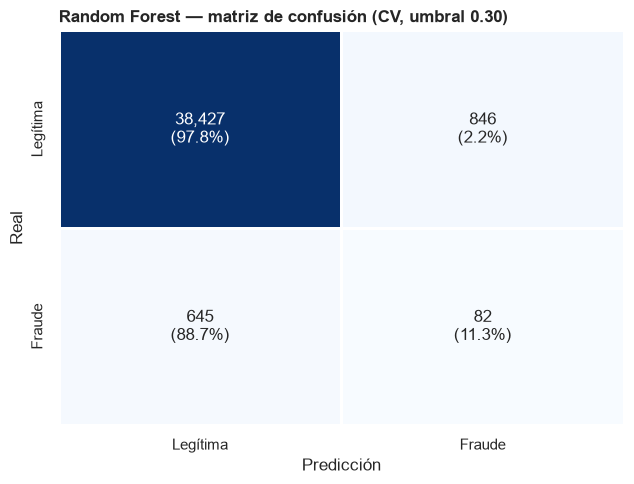

In [8]:
cm = confusion_matrix(y, pred)
etiquetas = np.array([[f"{v:,}\n({v / fila.sum() * 100:.1f}%)" for v in fila] for fila in cm])
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=etiquetas, fmt="", cmap="Blues", cbar=False, linewidths=1,
            xticklabels=["Legítima", "Fraude"], yticklabels=["Legítima", "Fraude"], ax=ax)
ax.set(xlabel="Predicción", ylabel="Real")
ax.set_title(f"Random Forest — matriz de confusión (CV, umbral {umbral:.2f})", loc="left", fontweight="bold")
guardar("rf_matriz_confusion")

Se presenta la matriz de confusión en formato de tabla con los conteos de cada caso.

In [9]:
pd.DataFrame(cm, index=pd.Index(["Legítima", "Fraude"], name="Real"),
             columns=pd.Index(["Legítima", "Fraude"], name="Predicción"))

Predicción,Legítima,Fraude
Real,,
Legítima,38427,846
Fraude,645,82


Se calculan la precisión, la sensibilidad (recall) y el F1-score de la clase fraude con el umbral óptimo.

In [10]:
tn, fp, fn, tp = cm.ravel()
pd.DataFrame({"valor": {"Umbral": umbral,
                        "Precision = VP / (VP + FP)": tp / (tp + fp),
                        "Sensibilidad (Recall) = VP / (VP + FN)": tp / (tp + fn),
                        "F1-score = 2·VP / (2·VP + FP + FN)": 2 * tp / (2 * tp + fp + fn)}})

,valor
Umbral,0.2962
Precision = VP / (VP + FP),0.0884
Sensibilidad (Recall) = VP / (VP + FN),0.1128
F1-score = 2·VP / (2·VP + FP + FN),0.0991


## 4. Curva Precision-Recall y capacidad de revisión

Se grafica la curva Precision-Recall fuera de fold frente a la línea base de un clasificador aleatorio, marcando el umbral óptimo.

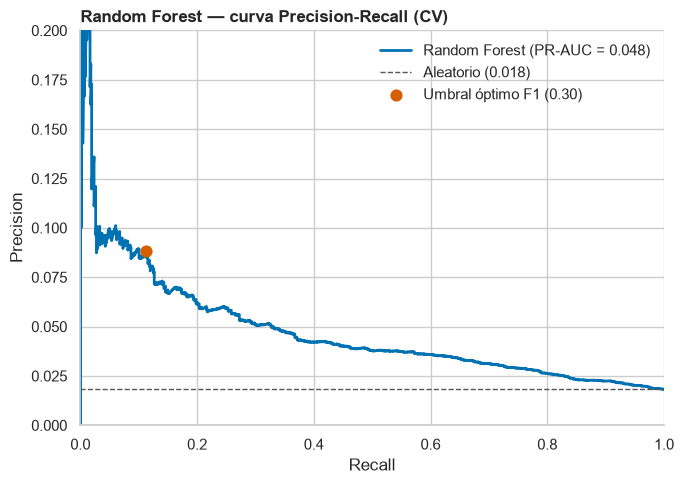

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.lineplot(x=rec, y=prec, estimator=None, sort=False, color="#0072B2", lw=2,
             label=f"Random Forest (PR-AUC = {average_precision_score(y, oof):.3f})", ax=ax)
ax.axhline(y.mean(), ls="--", color="#555", lw=1, label=f"Aleatorio ({y.mean():.3f})")
ax.scatter(rec[k], prec[k], color="#D55E00", s=60, zorder=3, label=f"Umbral óptimo F1 ({umbral:.2f})")
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 0.2))
ax.set_title("Random Forest — curva Precision-Recall (CV)", loc="left", fontweight="bold")
ax.legend(frameon=False)
sns.despine()
guardar("rf_curva_pr")

Se calcula cuántos fraudes se detectarían si el equipo antifraude revisara solo el porcentaje de transacciones con mayor probabilidad de fraude.

In [12]:
yv = y.values
filas = []
for pct in [1, 2, 5, 10, 20, 30]:
    u = np.quantile(oof, 1 - pct / 100)
    alerta = oof >= u
    tp_ = (alerta & (yv == 1)).sum()
    filas.append({"% revisado": pct, "umbral": u, "fraudes detectados": tp_,
                  "recall": tp_ / yv.sum(), "precision": tp_ / alerta.sum()})
pd.DataFrame(filas).set_index("% revisado")

,umbral,fraudes detectados,recall,precision
% revisado,,,,
1,0.3326,39,0.0536,0.0975
2,0.3036,71,0.0977,0.0887
5,0.2607,132,0.1816,0.0660
10,0.2247,211,0.2902,0.0527
20,0.1926,323,0.4443,0.0404
30,0.1635,432,0.5942,0.0360


## 5. Versión mejorada

El mejor modelo quedó en el borde de la búsqueda (profundidad 6 y sqrt, los valores más restrictivos probados) y con sobreajuste (PR-AUC train 0.12 vs validación 0.054); se prueban árboles menos profundos y menos variables por corte, que hacen los árboles más distintos entre sí y el promedio más estable.

In [13]:
grid_v2 = GridSearchCV(pipe, {"modelo__max_depth": [3, 4, 5],
                              "modelo__max_features": [0.05, 0.1, "sqrt"],
                              "modelo__min_samples_leaf": [50, 100],
                              "modelo__class_weight": [{0: 1, 1: 10}]},
                       cv=CV, scoring=SCORING, refit="pr_auc", return_train_score=True, n_jobs=-1)
grid_v2.fit(X, y)
print(f"Mejores parámetros: {grid_v2.best_params_} | PR-AUC CV: {grid_v2.best_score_:.4f}")

Mejores parámetros: {'modelo__class_weight': {0: 1, 1: 10}, 'modelo__max_depth': 3, 'modelo__max_features': 0.05, 'modelo__min_samples_leaf': 50} | PR-AUC CV: 0.0569


Se muestran las 8 mejores combinaciones de la versión mejorada con su PR-AUC en entrenamiento y validación y el cociente de sobreajuste.

In [14]:
cv2 = pd.DataFrame(grid_v2.cv_results_)
(cv2.assign(max_depth=cv2["param_modelo__max_depth"], max_features=cv2["param_modelo__max_features"].astype(str),
            min_samples_leaf=cv2["param_modelo__min_samples_leaf"],
            sobreajuste=cv2["mean_train_pr_auc"] / cv2["mean_test_pr_auc"])
    .set_index(["max_depth", "max_features", "min_samples_leaf"])
    [["mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "sobreajuste", "mean_test_roc_auc"]]
    .rename(columns=lambda c: c.replace("mean_", "").replace("test_", "val_"))
    .sort_values("val_pr_auc", ascending=False).head(8))

train_pr_auc  val_pr_auc  \
max_depth max_features min_samples_leaf                             
3         0.05         50                      0.0754      0.0569   
                       100                     0.0714      0.0563   
5         0.05         50                      0.0938      0.0560   
4         0.1          100                     0.0788      0.0557   
                       50                      0.0835      0.0557   
          0.05         50                      0.0842      0.0553   
5         0.1          100                     0.0879      0.0551   
3         sqrt         50                      0.0723      0.0551   

                                         std_val_pr_auc  sobreajuste  \
max_depth max_features min_samples_leaf                                
3         0.05         50                        0.0098       1.3243   
                       100                       0.0099       1.2674   
5         0.05         50                        0.0092       1.6746   
4         0.1          100                       0.0078       1.4140   
                       50                        0.0080       1.4991   
          0.05         50                        0.0096       1.5218   
5         0.1          100                       0.0089       1.5957   
3         sqrt         50                        0.0103       1.3123   

                                         val_roc_auc  
max_depth max_features min_samples_leaf               
3         0.05         50                     0.7007  
                       100                    0.7004  
5         0.05         50                     0.7027  
4         0.1          100                    0.7016  
                       50                     0.7025  
          0.05         50                     0.7034  
5         0.1          100                    0.7027  
3         sqrt         50                     0.6963

Se comparan las métricas de CV del Random Forest base y del mejorado, incluyendo el PR-AUC en entrenamiento para comparar el sobreajuste.

In [15]:
tabla = pd.concat({"base": resumen_cv(grid), "mejorado": resumen_cv(grid_v2)}, axis=1)
for nombre, g in [("base", grid), ("mejorado", grid_v2)]:
    tabla.loc["pr_auc_train", (nombre, "media")] = g.cv_results_["mean_train_pr_auc"][g.best_index_]
tabla

base        mejorado       
              media    std    media    std
métrica                                   
precision    0.0000 0.0000   0.0000 0.0000
recall       0.0000 0.0000   0.0000 0.0000
f1           0.0000 0.0000   0.0000 0.0000
roc_auc      0.6987 0.0197   0.7007 0.0261
pr_auc       0.0535 0.0103   0.0569 0.0098
pr_auc_train 0.1206    NaN   0.0754    NaN

Se elige como final la versión con mayor PR-AUC en CV y se obtienen sus probabilidades fuera de fold con el umbral que maximiza F1.

In [16]:
mejor = grid_v2 if grid_v2.best_score_ >= grid.best_score_ else grid
oof_mejor = cross_val_predict(mejor.best_estimator_, X, y, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
p2, r2, u2 = precision_recall_curve(y, oof_mejor)
f1_2 = 2 * p2 * r2 / (p2 + r2 + 1e-12)
k2 = f1_2[:-1].argmax()
umbral2 = u2[k2]
print(f"Versión final: {'mejorada' if mejor is grid_v2 else 'base'} | Umbral óptimo F1: {umbral2:.3f} | "
      f"alertas: {(oof_mejor >= umbral2).mean()*100:.1f}% de las transacciones")

Versión final: mejorada | Umbral óptimo F1: 0.185 | alertas: 3.6% de las transacciones


Se presenta la matriz de confusión fuera de fold de la versión final con su umbral óptimo.

In [17]:
cm2 = confusion_matrix(y, (oof_mejor >= umbral2).astype(int))
pd.DataFrame(cm2, index=pd.Index(["Legítima", "Fraude"], name="Real"),
             columns=pd.Index(["Legítima", "Fraude"], name="Predicción"))

Predicción,Legítima,Fraude
Real,,
Legítima,37943,1330
Fraude,615,112


Se calculan la precisión, la sensibilidad (recall) y el F1-score de la versión final con su umbral óptimo.

In [18]:
tn, fp, fn, tp = cm2.ravel()
pd.DataFrame({"valor": {"Umbral": umbral2,
                        "Precision = VP / (VP + FP)": tp / (tp + fp),
                        "Sensibilidad (Recall) = VP / (VP + FN)": tp / (tp + fn),
                        "F1-score = 2·VP / (2·VP + FP + FN)": 2 * tp / (2 * tp + fp + fn)}})

,valor
Umbral,0.1849
Precision = VP / (VP + FP),0.0777
Sensibilidad (Recall) = VP / (VP + FN),0.1541
F1-score = 2·VP / (2·VP + FP + FN),0.1033


Se calcula cuántos fraudes detectaría la versión final si el equipo antifraude revisara solo el porcentaje de transacciones de mayor riesgo.

In [19]:
filas = []
for pct in [1, 2, 5, 10, 20, 30]:
    u = np.quantile(oof_mejor, 1 - pct / 100)
    alerta = oof_mejor >= u
    tp_ = (alerta & (yv == 1)).sum()
    filas.append({"% revisado": pct, "umbral": u, "fraudes detectados": tp_,
                  "recall": tp_ / yv.sum(), "precision": tp_ / alerta.sum()})
pd.DataFrame(filas).set_index("% revisado")

,umbral,fraudes detectados,recall,precision
% revisado,,,,
1,0.1965,41,0.0564,0.1025
2,0.1904,68,0.0935,0.0850
5,0.1818,134,0.1843,0.0670
10,0.1757,204,0.2806,0.0510
20,0.1672,332,0.4567,0.0415
30,0.1606,428,0.5887,0.0357


## 6. Variables más influyentes

Se calcula la importancia por permutación de las 15 variables originales en la versión final: se entrena con 4 folds y, en el fold restante, se mide cuánto cae el PR-AUC al mezclar al azar cada variable.

In [20]:
from sklearn.base import clone

tr, va = next(CV.split(X, y))
modelo_pi = clone(mejor.best_estimator_).fit(X.iloc[tr], y.iloc[tr])
pi = permutation_importance(modelo_pi, X.iloc[va], y.iloc[va], scoring="average_precision",
                            n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importancia = (pd.DataFrame({"caída PR-AUC": pi.importances_mean, "desv.": pi.importances_std}, index=X.columns)
                 .sort_values("caída PR-AUC", ascending=False))
importancia

,caída PR-AUC,desv.
country,0.0215,0.0020
channel,0.0083,0.0057
amount_usd,0.0083,0.0042
merchant_category,0.0079,0.0031
amount_vs_avg,0.0074,0.0038
hour,0.0061,0.0029
new_device,0.0057,0.0026
distance_home_km,0.0041,0.0008
card_present,0.0028,0.0054
ip_risk_score,0.0020,0.0008


Se grafica la importancia por permutación con su desviación entre repeticiones.

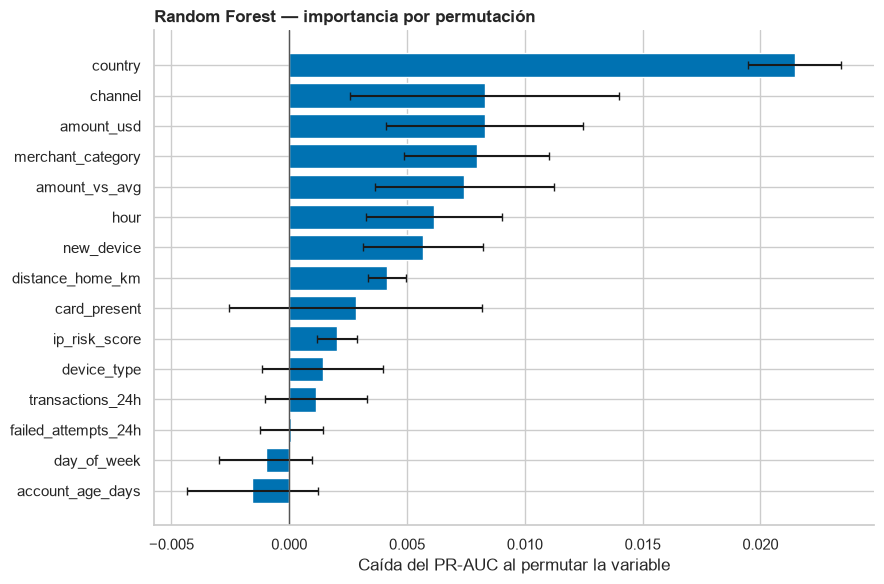

In [21]:
imp = importancia.sort_values("caída PR-AUC")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp.index, imp["caída PR-AUC"], xerr=imp["desv."], color="#0072B2", capsize=3)
ax.axvline(0, color="#555", lw=1)
ax.set(xlabel="Caída del PR-AUC al permutar la variable", ylabel="")
ax.set_title("Random Forest — importancia por permutación", loc="left", fontweight="bold")
sns.despine()
guardar("rf_importancia")

## 7. Guardado

Se guarda la versión final (la de mayor PR-AUC en CV) ajustada en todo train, con sus métricas de CV y sus probabilidades fuera de fold para la comparación final.

In [22]:
guardar_resultados("random_forest", mejor.best_estimator_, resumen_cv(mejor), y, oof_mejor)

['cv_random_forest.csv', 'oof_random_forest.csv', 'random_forest.joblib']

## 8. Conclusiones

- **Modelo final:** Random Forest mejorado (300 árboles, profundidad 3, 5% de las variables por corte, hoja mínima 50, peso de fraude ×10).
- **Rendimiento en CV (media ± desviación):** PR-AUC 0.057 ± 0.010 y ROC-AUC 0.701 ± 0.026; el PR-AUC en entrenamiento baja de 0.121 (base) a 0.075, reduciendo el sobreajuste (cociente train/validación 2.26 → 1.32). Es el mejor modelo hasta ahora, aunque su ventaja sobre la Regresión Logística (0.051 ± 0.008) queda dentro de la variación entre folds.
- **Con umbral 0.5 no alerta nada** (Precision y Recall = 0): con peso ×10 y árboles muy regularizados las probabilidades nunca llegan a 0.5; el umbral debe elegirse según la capacidad de revisión.
- **Con el umbral óptimo de F1 (0.18):** alerta el 3.6% de las transacciones con precisión del 7.8%, sensibilidad del 15.4% y F1 de 0.103 (112 fraudes detectados, 615 no detectados, 1,330 falsas alarmas).
- **Según capacidad de revisión:** revisando el 1% de mayor riesgo la precisión llega al 10.3%; revisando el 5% detecta el 18.4% de los fraudes con precisión del 6.7%.
- **Variables más influyentes (permutación):** country domina, seguida de channel, amount_usd, merchant_category, amount_vs_avg, hour y new_device; day_of_week, account_age_days, failed_attempts_24h y device_type no aportan (importancia ≈ 0).
- **Lectura:** los mejores bosques son los más simples (árboles poco profundos y pocas variables por corte); con una señal débil, la complejidad adicional solo aprende ruido. Aun así el modelo no alcanza la precisión que exige un sistema antifraude real.